In [1]:
import pandas as pd

In [2]:
!pip install -U scikit-learn==1.3.2 imbalanced-learn==0.11.0 --quiet
!pip install --upgrade lightgbm

In [3]:
df = pd.read_csv('../data/engine_fault_detection.csv')

In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("../data/engine_fault_detection.csv")

In [6]:
df.head()

,Vibration_Amplitude,RMS_Vibration,Vibration_Frequency,Surface_Temperature,Exhaust_Temperature,Acoustic_dB,Acoustic_Frequency,Intake_Pressure,Exhaust_Pressure,Frequency_Band_Energy,Amplitude_Mean,Engine_Condition
0,3.807947,1.899522,1465.396656,106.577348,319.564816,110.834195,3733.620495,91.279833,104.544934,0.889443,0.294582,0
1,9.512072,1.697915,385.333751,85.115094,237.927110,89.671023,4417.399188,114.855139,84.358093,0.916455,0.268216,0
2,7.346740,0.921962,706.346595,145.739823,250.543690,71.727937,2369.581389,97.479227,108.393914,0.440535,0.182008,0
3,6.026719,3.055970,1333.295661,56.277414,272.268451,104.198507,1516.975785,98.518121,105.296723,0.308468,0.251674,2
4,1.644585,2.409290,974.536902,100.542770,281.461334,85.120688,1662.348214,96.787358,107.565599,0.272495,0.188897,0


In [7]:
df.columns

Index(['Vibration_Amplitude', 'RMS_Vibration', 'Vibration_Frequency',
       'Surface_Temperature', 'Exhaust_Temperature', 'Acoustic_dB',
       'Acoustic_Frequency', 'Intake_Pressure', 'Exhaust_Pressure',
       'Frequency_Band_Energy', 'Amplitude_Mean', 'Engine_Condition'],
      dtype='str')

In [8]:
df.columns.tolist()

['Vibration_Amplitude',
 'RMS_Vibration',
 'Vibration_Frequency',
 'Surface_Temperature',
 'Exhaust_Temperature',
 'Acoustic_dB',
 'Acoustic_Frequency',
 'Intake_Pressure',
 'Exhaust_Pressure',
 'Frequency_Band_Energy',
 'Amplitude_Mean',
 'Engine_Condition']

In [9]:
df.shape

(10000, 12)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Vibration_Amplitude    10000 non-null  float64
 1   RMS_Vibration          10000 non-null  float64
 2   Vibration_Frequency    10000 non-null  float64
 3   Surface_Temperature    10000 non-null  float64
 4   Exhaust_Temperature    10000 non-null  float64
 5   Acoustic_dB            10000 non-null  float64
 6   Acoustic_Frequency     10000 non-null  float64
 7   Intake_Pressure        10000 non-null  float64
 8   Exhaust_Pressure       10000 non-null  float64
 9   Frequency_Band_Energy  10000 non-null  float64
 10  Amplitude_Mean         10000 non-null  float64
 11  Engine_Condition       10000 non-null  int64  
dtypes: float64(11), int64(1)
memory usage: 937.6 KB


In [11]:
df['Engine_Condition'].value_counts()

Engine_Condition
0    5963
1    3037
2    1000
Name: count, dtype: int64

In [12]:
df.describe()

,Vibration_Amplitude,RMS_Vibration,Vibration_Frequency,Surface_Temperature,Exhaust_Temperature,Acoustic_dB,Acoustic_Frequency,Intake_Pressure,Exhaust_Pressure,Frequency_Band_Energy,Amplitude_Mean,Engine_Condition
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992180,2.547423,1010.099781,89.845606,398.745522,90.188675,2558.761766,104.976734,95.031300,0.545828,0.255133,0.503700
std,2.847538,1.432008,567.812039,34.679351,115.713672,17.300477,1409.523813,8.579042,8.749599,0.258961,0.141254,0.670844
min,0.100115,0.050781,20.095285,30.000664,200.006695,60.000506,101.323600,90.003900,80.003865,0.100026,0.010048,0.000000
25%,2.538656,1.307032,522.420864,59.622870,297.708889,75.417389,1344.035229,97.559952,87.314803,0.320392,0.130852,0.000000
50%,4.976033,2.554189,1014.094827,90.003629,397.486877,90.365423,2570.626283,104.976943,95.127134,0.546940,0.256507,0.000000
75%,7.426063,3.794572,1494.454231,119.653950,500.190814,105.206758,3787.099025,112.434660,102.769823,0.768050,0.377475,1.000000
max,9.997205,4.999628,1999.803934,149.974725,599.988859,119.996382,4998.480399,119.996253,109.999761,0.999978,0.499890,2.000000


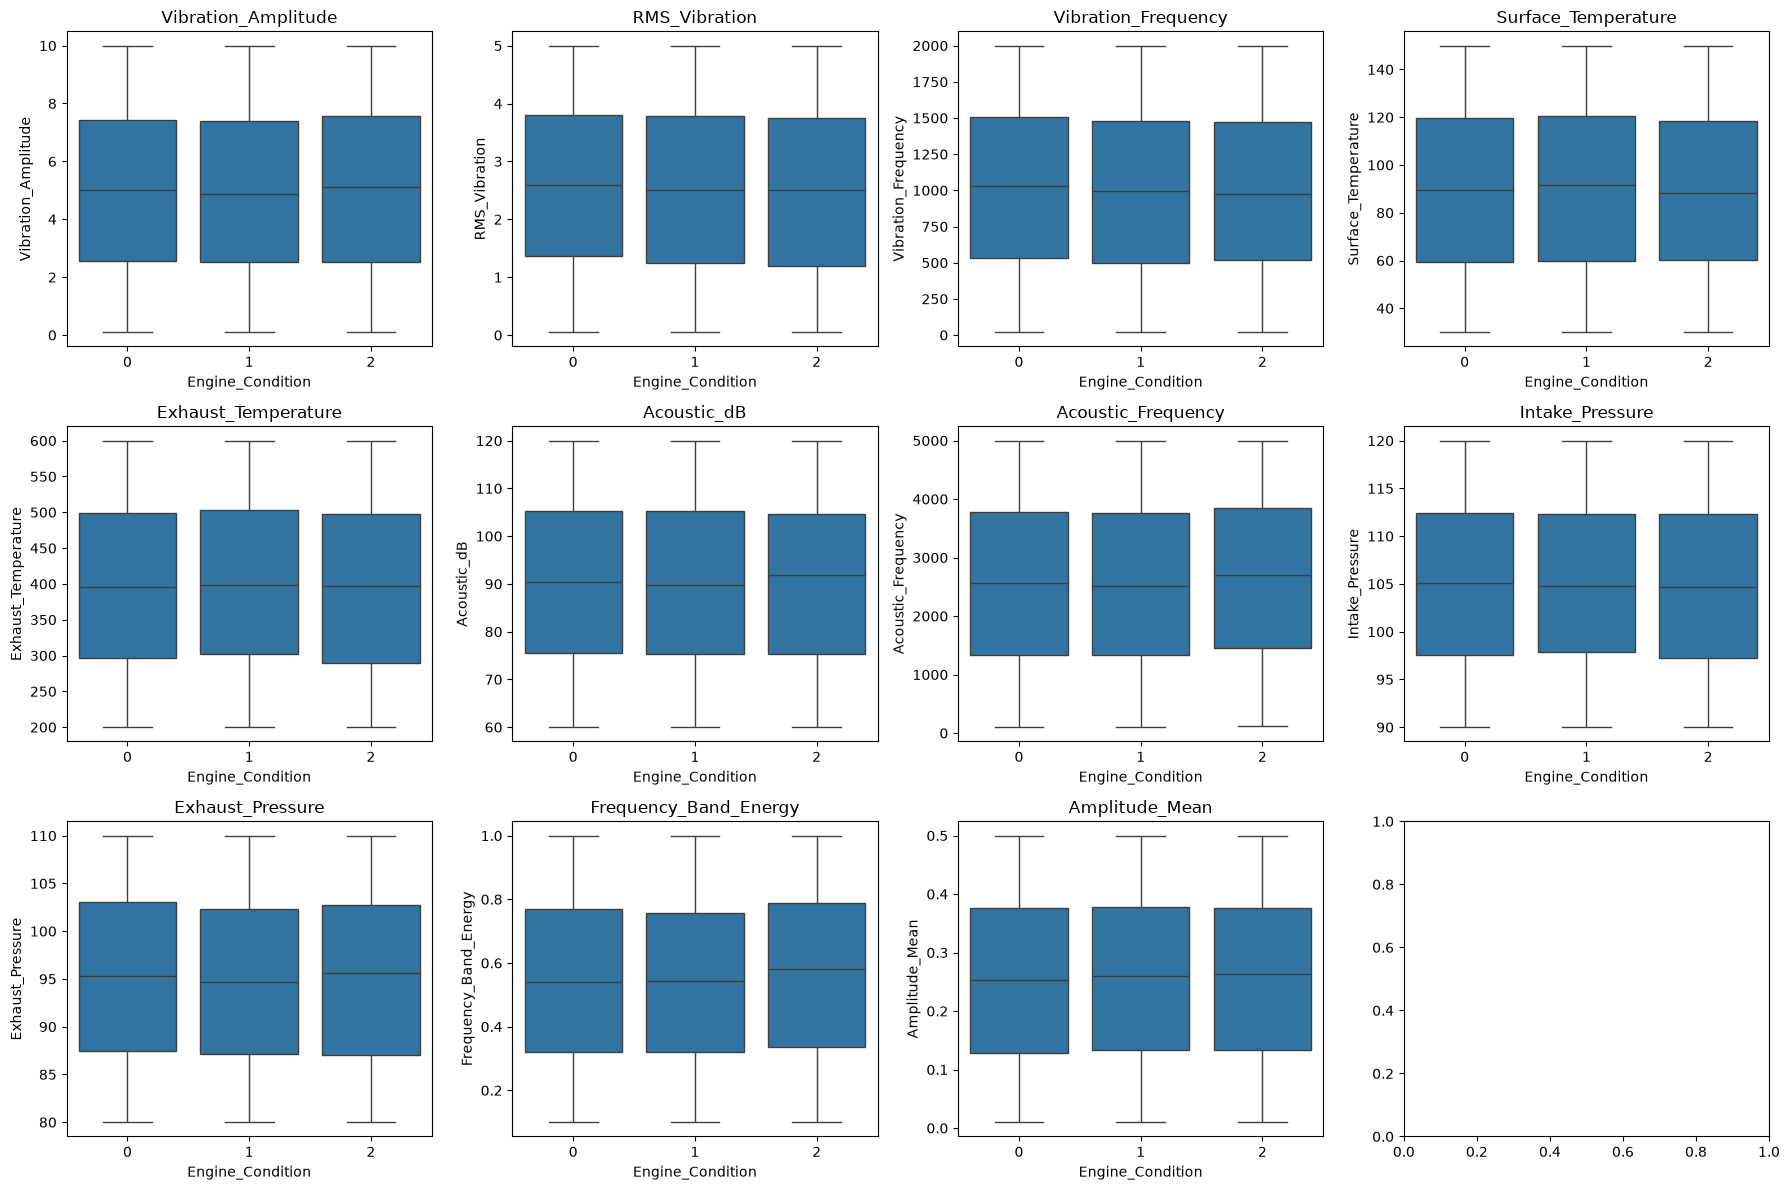

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
features = ['Vibration_Amplitude', 'RMS_Vibration', 'Vibration_Frequency',
            'Surface_Temperature', 'Exhaust_Temperature', 'Acoustic_dB',
            'Acoustic_Frequency', 'Intake_Pressure', 'Exhaust_Pressure',
            'Frequency_Band_Energy', 'Amplitude_Mean']

for i, col in enumerate(features):
    ax = axes[i // 4, i % 4]
    sns.boxplot(data=df, x='Engine_Condition', y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

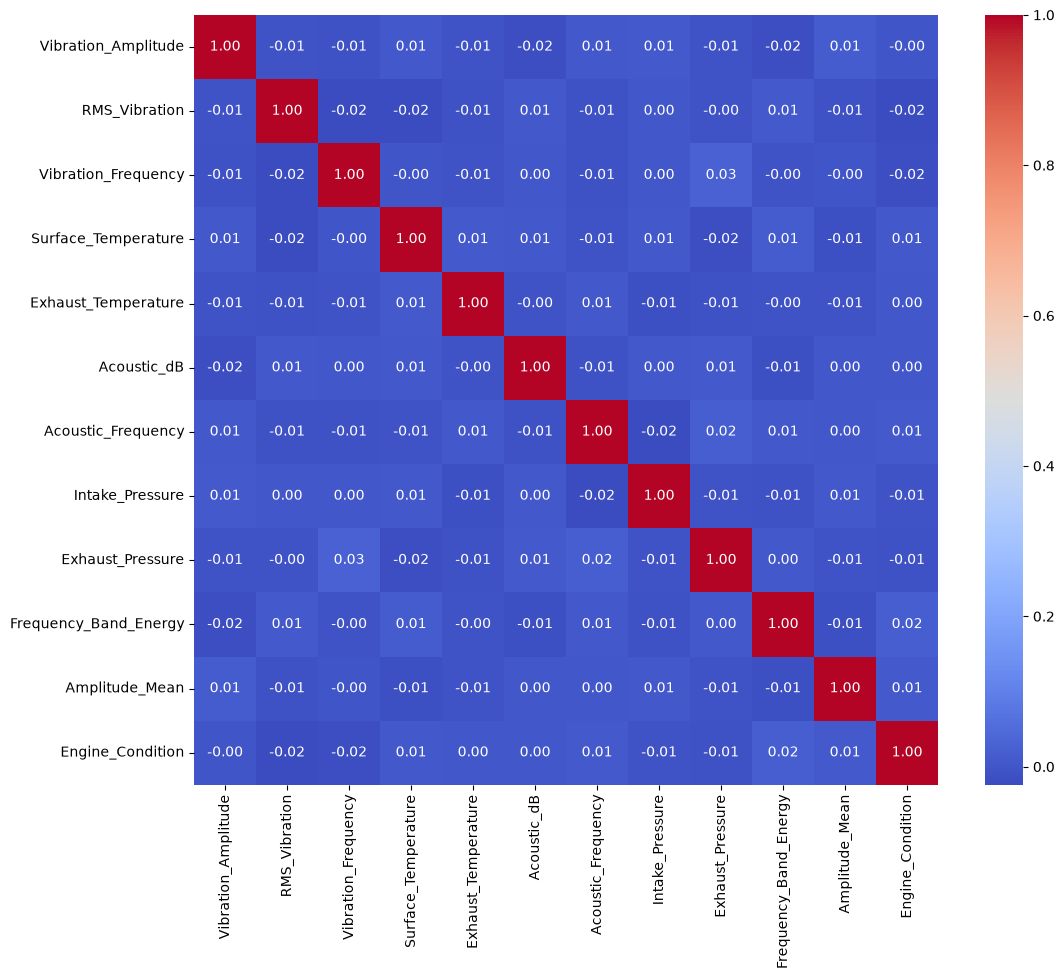

In [14]:

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

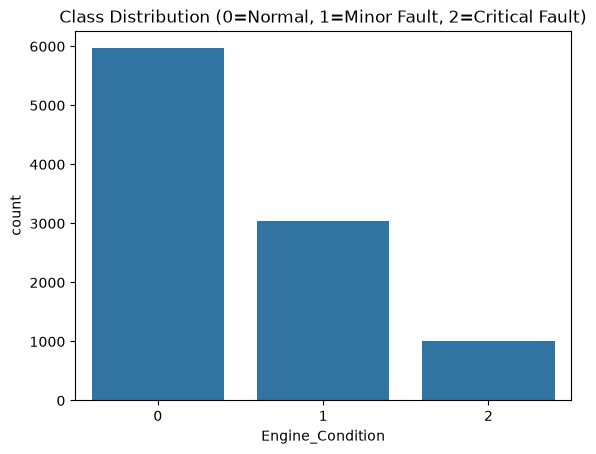

In [15]:
# Class distribution
sns.countplot(x="Engine_Condition", data=df)
plt.title("Class Distribution (0=Normal, 1=Minor Fault, 2=Critical Fault)")
plt.show()


In [16]:
from sklearn.model_selection import train_test_split

X = df.drop('Engine_Condition', axis=1)
y = df['Engine_Condition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(8000, 11) (2000, 11)


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

log_reg = LogisticRegression(class_weight='balanced', random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.62      0.29      0.40      1193
           1       0.33      0.35      0.34       607
           2       0.10      0.41      0.17       200

    accuracy                           0.32      2000
   macro avg       0.35      0.35      0.30      2000
weighted avg       0.48      0.32      0.36      2000



In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.60      0.99      0.75      1193
           1       0.43      0.02      0.03       607
           2       0.00      0.00      0.00       200

    accuracy                           0.60      2000
   macro avg       0.34      0.34      0.26      2000
weighted avg       0.49      0.60      0.45      2000



/opt/miniconda3/envs/python311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/miniconda3/envs/python311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/miniconda3/envs/python311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [20]:
rf2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
rf2.fit(X_train, y_train)

y_pred_rf2 = rf2.predict(X_test)
print(classification_report(y_test, y_pred_rf2))

              precision    recall  f1-score   support

           0       0.60      0.82      0.69      1193
           1       0.33      0.17      0.23       607
           2       0.13      0.04      0.05       200

    accuracy                           0.54      2000
   macro avg       0.35      0.34      0.32      2000
weighted avg       0.47      0.54      0.49      2000



In [21]:
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss')
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.59      0.86      0.70      1193
           1       0.31      0.13      0.18       607
           2       0.00      0.00      0.00       200

    accuracy                           0.55      2000
   macro avg       0.30      0.33      0.29      2000
weighted avg       0.45      0.55      0.47      2000



In [22]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(y_train_smote.value_counts())

Engine_Condition
0    4770
2    4770
1    4770
Name: count, dtype: int64


In [23]:
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test)
print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.60      0.67      0.63      1193
           1       0.32      0.24      0.28       607
           2       0.12      0.13      0.13       200

    accuracy                           0.49      2000
   macro avg       0.35      0.35      0.35      2000
weighted avg       0.47      0.49      0.47      2000



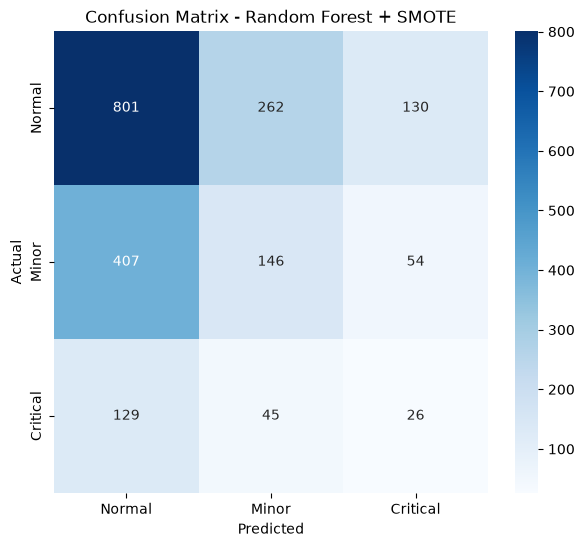

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Minor', 'Critical'],
            yticklabels=['Normal', 'Minor', 'Critical'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest + SMOTE')
plt.show()

In [25]:
import joblib

# Save the trained model
joblib.dump(rf_smote, '../models/engine_fault_model.pkl')

print("Model saved successfully!")

Model saved successfully!
